# Task 7 — GJR-GARCH (Asymmetric) Volatility-Scaled Historical Simulation
### QFI Internship · Market Risk Project · Phase 7
**Prepared by:** Arham Shah

---

**Objective.** Task 6's GARCH(1,1) treats a −3% day and a +3% day the same. Equity volatility doesn't behave that way: losses push future volatility up more than equal-sized gains do (the *leverage effect*). This task **tests for the asymmetry first**, then models it with GJR-GARCH and checks whether it improves the VaR.

**What this notebook delivers**
- **Evidence before modelling:** next-day volatility after down vs up days, and the Engle–Ng sign-bias test on Task 6's GARCH residuals
- GJR-GARCH(1,1,1) MLE (Normal / Student-t) on the same engine as Task 6, **cross-checked against `arch`**
- A **likelihood-ratio test** of GJR against GARCH, using the correct boundary distribution
- **News-impact curves** for EWMA, GARCH and GJR, so the asymmetry is visible
- **Out-of-sample** GJR-FHS VaR and ES (refitted monthly) and the stability of γ over time
- A head-to-head with GARCH on identical dates: asymmetric reaction speed and exceptions
- Export to `GJR_VaR.csv` and an update to `VaR_Model_Summary.csv`, ready for Tasks 8 and 9

> **Pipeline:** Task 3 Portfolio → Task 4 HS → Task 5 EWMA → Task 6 GARCH → **Task 7 GJR-GARCH** → Task 8 Backtesting → Task 9 Model selection → Task 10 →

> **How to run:** Colab → *Runtime → Run all*. Running it after Task 3 in the same session means it uses `Portfolio_Construction.csv`. Otherwise it rebuilds that portfolio with the same Task 3 engine, so the numbers match.

## 1. The leverage effect and the GJR model
$$\sigma_t^2=\omega+\big(\alpha+\gamma\,\mathbf 1_{\{\varepsilon_{t-1}<0\}}\big)\varepsilon_{t-1}^2+\beta\,\sigma_{t-1}^2$$

| Shock | Contribution to tomorrow's variance |
|---|---|
| Gain (ε > 0) | α ε² |
| Loss (ε < 0) | (α + γ) ε² |

- **γ > 0** is the leverage effect, and **γ = 0** gives back Task 6's GARCH exactly. GJR *nests* GARCH, so we can test it formally.
- Persistence = α + β + γ/2, because on average half of all shocks are negative.
- The Hull–White step is the same as before: z = r/σ, and VaR_t = −σ_t·Q(z). σ_t now jumps further after *losses*, which is when VaR coverage matters most.

**Why it might happen.** A falling price raises a firm's financial leverage, so its equity becomes riskier. Sell-offs also trigger de-risking and margin calls that feed on themselves. Rallies do neither.

## Conventions used in every VaR task (4 → 9)
| Convention | Choice | Why |
|---|---|---|
| Horizon | 1 trading day | Standard for daily risk limits and backtesting |
| Timing | VaR for day *t* uses data up to *t − 1* only | No look-ahead, so it is a genuine forecast that can be backtested |
| Sign | VaR and ES are **positive losses** | Easier to read: "we could lose $X" |
| Units | Model on **returns**, then convert to dollars with the **start-of-day value** | The portfolio grew from $1M to $4.5M, so old dollar P&L understates today's risk |
| Exception | Return < −VaR (equivalently P&L < −VaR$) | Basel definition |
| Headline | 99% confidence, 250-day window | Basel internal-models standard |
| Export | `<MODEL>_VaR.csv` with identical column patterns | Task 8 and Task 9 can read every model the same way |

In [1]:
# ---- Setup ---------------------------------------------------------------
import os, json, time, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from numpy.lib.stride_tricks import sliding_window_view
from scipy import stats
from scipy.signal import lfilter
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
plt.rcParams.update({
    'figure.figsize': (13, 5), 'figure.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.3, 'axes.titleweight': 'bold',
    'axes.titlesize': 13, 'legend.frameon': False,
})
AUTHOR = 'Arham Shah'
print(f'Environment ready | pandas {pd.__version__} | numpy {np.__version__} | run by {AUTHOR}')

try:
    import arch                                     # optional: cross-check + robust standard errors
    HAS_ARCH = True
except ImportError:
    try:
        %pip install -q arch
        import arch; HAS_ARCH = True
    except Exception:
        HAS_ARCH = False
print('arch package available:', HAS_ARCH)

Environment ready | pandas 2.2.2 | numpy 1.26.4 | run by Arham Shah


arch package available: True


In [2]:
# ---- Project configuration (identical across Tasks 1-10) ------------------
UNIVERSE = {'AAPL': 'Information Technology', 'MSFT': 'Information Technology',
            'NVDA': 'Information Technology', 'GOOGL': 'Communication Services',
            'META': 'Communication Services', 'AMZN': 'Consumer Discretionary',
            'TSLA': 'Consumer Discretionary', 'JPM': 'Financials',
            'XOM': 'Energy', 'UNH': 'Health Care'}
TICKERS, BENCHMARK = list(UNIVERSE), '^GSPC'
START_DATE, END_DATE = '2020-07-24', '2026-07-25'
INITIAL_VALUE, REBALANCE, COST_BPS = 1_000_000, 'M', 5        # Task 3 portfolio
TRADING_DAYS = 252
PORTFOLIO_FILE = 'Portfolio_Construction.csv'                  # Task 3 output

# ---- Risk-model settings shared by every VaR model (Tasks 4-9) ----
WINDOWS     = (250, 500, 750)          # ~1, 2, 3 years of history
CONFIDENCES = (0.95, 0.99, 0.995)
HEADLINE_W, HEADLINE_CL = 250, 0.99    # Basel-style headline: 99%, 1-year window
EWMA_LAMBDA = 0.94                     # RiskMetrics daily decay (same as Task 2)
CCY = '$'
SUMMARY_FILE = 'VaR_Model_Summary.csv' # one row per model x window x confidence

COLORS = {'HS': '#E08A2E', 'EWMA': '#6A2C91', 'GARCH': '#1F7A8C',
          250: '#E08A2E', 500: '#C0392B', 750: '#5B2C6F',
          'loss': '#B03A2E', 'gain': '#2E7D68', 'muted': '#8C99A6', 'ink': '#1B2A41'}

def tag(c):   return f'{100*c:g}'.replace('.', 'p')          # 0.995 -> '99p5'
def pct(x, dp=2):   return 'n/a' if not np.isfinite(x) else f'{100*x:.{dp}f}%'
def money(x, dp=0): return 'n/a' if not np.isfinite(x) else f'{CCY}{x:,.{dp}f}'
usd_fmt = mtick.FuncFormatter(lambda x, _: f'{CCY}{x/1e3:,.0f}k')
print(f'Windows {WINDOWS} | confidences {CONFIDENCES} | headline {HEADLINE_CL:.0%} / {HEADLINE_W}d')

Windows (250, 500, 750) | confidences (0.95, 0.99, 0.995) | headline 99% / 250d


## 2. Load the portfolio, the shared toolkit and the volatility engine
The engine is the same code as Task 6, with γ = 0 switched on or off. We check that it reproduces Task 6's GARCH forecasts exactly.

In [3]:
# ---- Load the Task 3 portfolio (or rebuild it identically if missing) -----
def rebuild_portfolio():
    """Re-creates Task 3's monthly-rebalanced equal-weight portfolio from Yahoo data."""
    try:
        import yfinance as yf
    except ImportError:
        %pip install -q yfinance
        import yfinance as yf
    def adj(symbols):
        px = yf.download(symbols, start=START_DATE, end=END_DATE, auto_adjust=False, progress=False)['Adj Close']
        return px.to_frame(symbols[0]) if isinstance(px, pd.Series) else px
    bench = adj([BENCHMARK]).iloc[:, 0].dropna()
    px = adj(TICKERS)[TICKERS].reindex(bench.index).ffill(limit=3).dropna()
    rets = px.pct_change().iloc[1:]
    w, c = np.repeat(1 / len(TICKERS), len(TICKERS)), COST_BPS / 1e4
    s = pd.Series(rets.index, index=rets.index)
    rb = set(s.groupby(rets.index.to_period(REBALANCE)).max()) - {rets.index[-1]}
    h = INITIAL_VALUE / (1 + c) * w
    vals = [h.sum()]
    for d, r in zip(rets.index, rets.values):
        h = h * (1 + r); V = h.sum()
        if d in rb:
            V -= np.abs(V * w - h).sum() * c; h = V * w
        vals.append(V)
    v = pd.Series(vals, index=px.index)
    out = pd.DataFrame({'Return': v.pct_change(), 'Value': v, 'PnL': v.diff()})
    out.iloc[0] = [v.iloc[0] / INITIAL_VALUE - 1, v.iloc[0], v.iloc[0] - INITIAL_VALUE]
    out['Benchmark_Return'] = bench.reindex(out.index).pct_change()
    out.index.name = 'Date'
    out.to_csv(PORTFOLIO_FILE)
    return out

if os.path.exists(PORTFOLIO_FILE):
    raw = pd.read_csv(PORTFOLIO_FILE, index_col=0, parse_dates=True)
    SOURCE = f'{PORTFOLIO_FILE} (Task 3 output)'
else:
    raw = rebuild_portfolio()
    SOURCE = 'rebuilt from Yahoo Finance with the Task 3 engine (file not found)'

pf = raw[['Return', 'PnL', 'Value']].astype(float).copy()
pf['Start_Value'] = pf['Value'].shift(1)            # capital at risk at the start of each day
pf = pf.iloc[1:]                                    # drop day 0 (purchase day, not a market move)
assert np.allclose(pf['PnL'], pf['Return'] * pf['Start_Value']), 'P&L / return mismatch'
assert pf.isna().sum().sum() == 0, 'unexpected gaps in the portfolio series'

returns, pnl, start_value = pf['Return'], pf['PnL'], pf['Start_Value']
NAV = float(pf['Value'].iloc[-1])
print(f'Source : {SOURCE}')
print(f'Sample : {returns.index[0]:%d %b %Y} -> {returns.index[-1]:%d %b %Y} ({len(returns):,} daily returns)')
print(f'NAV    : {money(NAV)} | realised vol {pct(returns.std() * np.sqrt(TRADING_DAYS))} p.a.')

Source : Portfolio_Construction.csv (Task 3 output)
Sample : 27 Jul 2020 -> 24 Jul 2026 (1,506 daily returns)
NAV    : $4,520,228 | realised vol 22.97% p.a.


In [4]:
# ---- Shared risk toolkit (identical in Tasks 4-6) -------------------------
def var_es(x, c):
    """Empirical VaR and ES of a return sample, as POSITIVE losses."""
    x = np.asarray(x, float); q = np.quantile(x, 1 - c)
    return -q, -x[x <= q].mean()

def rolling_hs(r, window, c):
    """One-day-ahead rolling HS VaR/ES. The value on day t uses r[t-W .. t-1] only."""
    v = np.asarray(r, float)
    out = pd.DataFrame(np.nan, index=r.index, columns=['VaR', 'ES'])
    if len(v) <= window:
        return out
    sw = sliding_window_view(v[:-1], window)          # row i = v[i : i+W] -> forecast for day i+W
    q = np.quantile(sw, 1 - c, axis=1)
    m = sw <= q[:, None]
    out.iloc[window:, 0] = -q
    out.iloc[window:, 1] = -(sw * m).sum(1) / m.sum(1)
    return out

def rolling_fhs(r, sigma, window, c):
    """Filtered HS (Hull-White): replay standardised shocks z = r/sigma at today's sigma."""
    return rolling_hs(r / sigma, window, c).mul(sigma, axis=0)

def kupiec(x, n, c):
    """Kupiec proportion-of-failures LR test -> (LR, p-value)."""
    p = 1 - c
    if n == 0: return np.nan, np.nan
    ph = x / n
    ll0 = (n - x) * np.log(1 - p) + x * np.log(p)
    ll1 = (n - x) * np.log(1 - ph) + (x * np.log(ph) if x > 0 else 0) if ph < 1 else 0
    lr = -2 * (ll0 - ll1)
    return lr, 1 - stats.chi2.cdf(lr, 1)

def basel_zone(x250):
    return 'GREEN' if x250 <= 4 else ('YELLOW' if x250 <= 9 else 'RED')
BASEL_MULT = {**{k: 3.0 for k in range(5)}, 5: 3.4, 6: 3.5, 7: 3.65, 8: 3.75, 9: 3.85}

def ljung_box(x, lags=10):
    x = np.asarray(x, float); x = x - x.mean(); n = len(x); d = x @ x
    rho = np.array([(x[k:] @ x[:-k]) / d for k in range(1, lags + 1)])
    q = n * (n + 2) * np.sum(rho**2 / (n - np.arange(1, lags + 1)))
    return q, 1 - stats.chi2.cdf(q, lags)

def backtest_table(model, panel, r=None, dates=None):
    """Exception counts + Kupiec + Basel zone for every (window, confidence)."""
    r = returns if r is None else r
    rows = []
    for (w, c), df in panel.items():
        f = df['VaR'].dropna()
        if dates is not None: f = f.loc[f.index.intersection(dates)]
        hit = r.reindex(f.index) < -f
        n, x = len(f), int(hit.sum())
        lr, p = kupiec(x, n, c)
        x250 = int(hit.iloc[-250:].sum())
        rows.append({'Model': model, 'Window': w, 'Confidence': c,
                     'Start': f.index[0].date(), 'Days': n, 'Exceptions': x,
                     'Expected': n * (1 - c), 'Rate': x / n, 'Kupiec p': p,
                     'Kupiec': 'PASS' if p > 0.05 else 'REJECT',
                     'Last 250d exc.': x250,
                     'Basel zone': basel_zone(x250) if c == 0.99 else '-',
                     'Avg VaR %': f.mean(), 'Avg ES %': df['ES'].reindex(f.index).mean(),
                     'VaR churn %': f.diff().abs().mean()})
    return pd.DataFrame(rows)

def style_bt(t):
    zc = {'GREEN': '#2E7D68', 'YELLOW': '#C78B00', 'RED': '#B03A2E', 'PASS': '#2E7D68', 'REJECT': '#B03A2E'}
    return (t.style.format({'Confidence': '{:.1%}', 'Expected': '{:.1f}', 'Rate': '{:.2%}', 'Kupiec p': '{:.3f}',
                            'Avg VaR %': '{:.2%}', 'Avg ES %': '{:.2%}', 'VaR churn %': '{:.3%}'})
             .map(lambda v: f'color:{zc[v]};font-weight:bold' if v in zc else '', subset=['Kupiec', 'Basel zone'])
             .hide(axis='index'))

def export_model(model, panel, fname):
    """Uniform export schema consumed by Task 8 (backtesting) and Task 9 (comparison)."""
    out = pf[['Return', 'PnL', 'Start_Value']].copy()
    for (w, c), df in panel.items():
        k = f'{model}_{{}}_{w}d_{tag(c)}'
        out[k.format('VaR') + '_Ret'] = df['VaR']
        out[k.format('ES') + '_Ret'] = df['ES']
        out[k.format('VaR')] = df['VaR'] * pf['Start_Value']
        out[k.format('ES')] = df['ES'] * pf['Start_Value']
        out[k.format('Breach')] = (pf['Return'] < -df['VaR']).astype(float).where(df['VaR'].notna())
    out.to_csv(fname, date_format='%Y-%m-%d')
    dd = pd.DataFrame([
        ('Return', 'decimal', 'Realised daily portfolio return (Task 3)'),
        ('PnL', CCY, 'Realised daily P&L = Return x Start_Value'),
        ('Start_Value', CCY, 'Portfolio value at the start of the day (capital at risk)'),
        (f'{model}_VaR_<W>d_<CL>_Ret', 'positive decimal', 'One-day-ahead VaR forecast as a return (uses data to t-1 only)'),
        (f'{model}_ES_<W>d_<CL>_Ret', 'positive decimal', 'One-day-ahead Expected Shortfall as a return'),
        (f'{model}_VaR_<W>d_<CL>', CCY, 'VaR in dollars = VaR_Ret x Start_Value'),
        (f'{model}_ES_<W>d_<CL>', CCY, 'ES in dollars = ES_Ret x Start_Value'),
        (f'{model}_Breach_<W>d_<CL>', '1/0/NaN', '1 if Return < -VaR (an exception); NaN before the first forecast'),
    ], columns=['Column', 'Unit', 'Definition'])
    dd.to_csv(fname.replace('.csv', '_Dictionary.csv'), index=False)
    print(f'Saved {fname} ({out.shape[0]:,} rows x {out.shape[1]} cols) + data dictionary')
    return out

def update_summary(bt, next_day):
    """Upsert this model's rows into the shared cross-model summary file."""
    rows = bt.copy()
    rows['Next-day VaR %'] = [next_day[(w, c)][0] for w, c in zip(rows['Window'], rows['Confidence'])]
    rows['Next-day ES %'] = [next_day[(w, c)][1] for w, c in zip(rows['Window'], rows['Confidence'])]
    rows['Next-day VaR $'] = rows['Next-day VaR %'] * NAV
    rows['Next-day ES $'] = rows['Next-day ES %'] * NAV
    rows['Updated'] = datetime.now().isoformat(timespec='seconds')
    if os.path.exists(SUMMARY_FILE):
        old = pd.read_csv(SUMMARY_FILE)
        rows = pd.concat([old[old['Model'] != rows['Model'].iloc[0]], rows], ignore_index=True)
    rows.to_csv(SUMMARY_FILE, index=False)
    print(f'{SUMMARY_FILE} now holds models: {sorted(rows["Model"].unique())}')

print('Risk toolkit loaded.')

Risk toolkit loaded.


In [5]:
# ---- Shared volatility engine: EWMA (Task 5), GARCH (Task 6), GJR (Task 7) ----
from scipy.optimize import minimize
from scipy.special import gammaln
REFIT_EVERY, MIN_EST, EWMA_SEED = 21, 500, 30

def ewma_sigma(r, lam=EWMA_LAMBDA, seed=EWMA_SEED):
    e2 = np.asarray(r, float) ** 2; h0 = e2[:seed].mean()
    h = np.r_[h0, lfilter([1 - lam], [1, -lam], e2[:-1], zi=[lam * h0])[0]]
    return pd.Series(np.sqrt(h), index=r.index)

def backcast(e, n=75):
    w = 0.94 ** np.arange(min(n, len(e))); w /= w.sum()
    return float(w @ e[:len(w)] ** 2)

def vol_var(e, omega, alpha, beta, gamma=0.0):
    """h_t = omega + (alpha + gamma*1[e_{t-1}<0]) e_{t-1}^2 + beta h_{t-1}.  gamma = 0 -> GARCH(1,1)."""
    h0 = backcast(e)
    u = omega + (alpha + gamma * (e[:-1] < 0)) * e[:-1] ** 2
    return np.r_[h0, lfilter([1.0], [1.0, -beta], u, zi=[beta * h0])[0]]

def nll(p, x, dist, asym):
    mu, omega, alpha, beta = p[:4]
    gamma = p[4] if asym else 0.0
    e = x - mu
    h = np.maximum(vol_var(e, omega, alpha, beta, gamma), 1e-10)
    if dist == 'normal':
        ll = -0.5 * (np.log(2 * np.pi) + np.log(h) + e * e / h)
    else:
        nu = p[-1]
        ll = (gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
              - 0.5 * np.log(h) - (nu + 1) / 2 * np.log1p(e * e / (h * (nu - 2))))
    return -ll.sum()

def fit_vol(r, dist='normal', asym=False, x0=None):
    """Gaussian or Student-t (Q)MLE of GARCH(1,1) or GJR-GARCH(1,1,1). Returns in percent units internally."""
    x = np.asarray(r, float) * 100
    v = x.var()
    tb = [(2.1, 100)] if dist == 't' else []
    if asym:
        x0 = x0 if x0 is not None else [x.mean(), 0.05 * v, 0.02, 0.88, 0.10] + ([8.0] if dist == 't' else [])
        bnds = [(-2, 2), (1e-6, 10 * v), (0.0, 0.5), (0.0, 0.9999), (0.0, 0.5)] + tb
        con = lambda p: 0.9999 - p[2] - p[3] - 0.5 * p[4]
    else:
        x0 = x0 if x0 is not None else [x.mean(), 0.05 * v, 0.08, 0.88] + ([8.0] if dist == 't' else [])
        bnds = [(-2, 2), (1e-6, 10 * v), (1e-6, 0.5), (0.0, 0.9999)] + tb
        con = lambda p: 0.9999 - p[2] - p[3]
    res = minimize(nll, x0, args=(x, dist, asym), method='SLSQP', bounds=bnds,
                   constraints={'type': 'ineq', 'fun': con}, options={'maxiter': 500, 'ftol': 1e-10})
    p = res.x
    gamma = p[4] if asym else 0.0
    pers = p[2] + p[3] + 0.5 * gamma
    k, ll = len(p), -res.fun
    return {'dist': dist, 'asym': asym, 'mu': p[0] / 100, 'omega': p[1] / 1e4, 'alpha': p[2], 'beta': p[3],
            'gamma': gamma, 'nu': p[-1] if dist == 't' else np.nan, 'persistence': pers,
            'long_run_vol_ann': np.sqrt(p[1] / 1e4 / (1 - pers) * TRADING_DAYS),
            'half_life': np.log(0.5) / np.log(pers), 'loglik': ll,
            'aic': 2 * k - 2 * ll, 'bic': k * np.log(len(x)) - 2 * ll, 'converged': bool(res.success), '_x': p}

def vol_sigma(r, P):
    """One-day-ahead conditional sigma_t (decimal) for the whole series under parameters P."""
    e = (np.asarray(r, float) - P['mu']) * 100
    return pd.Series(np.sqrt(vol_var(e, P['omega'] * 1e4, P['alpha'], P['beta'], P['gamma'])) / 100, index=r.index)

def vol_next(r, P):
    e = np.asarray(r, float) - P['mu']
    h = vol_sigma(r, P).iloc[-1] ** 2
    return float(np.sqrt(P['omega'] + (P['alpha'] + P['gamma'] * (e[-1] < 0)) * e[-1] ** 2 + P['beta'] * h))

def oos_fhs(r, dist, asym):
    """Filtered HS with the volatility model re-estimated every REFIT_EVERY days on past data only."""
    n = len(r)
    sig_oos = pd.Series(np.nan, index=r.index)
    panel = {(w, c): pd.DataFrame(np.nan, index=r.index, columns=['VaR', 'ES']) for w in WINDOWS for c in CONFIDENCES}
    hist, x0 = [], None
    for b in range(MIN_EST, n, REFIT_EVERY):
        P = fit_vol(r.iloc[:b], dist, asym, x0); x0 = P['_x']
        end = min(b + REFIT_EVERY, n)
        rr = r.iloc[:end]
        s = vol_sigma(rr, P)
        zz = (rr / s).to_numpy()
        sig_oos.iloc[b:end] = s.iloc[b:end].values
        for (w, c), df in panel.items():
            lo = max(b, w)
            if lo >= end: continue
            sw = sliding_window_view(zz[lo - w:end - 1], w)
            q = np.quantile(sw, 1 - c, axis=1); m = sw <= q[:, None]
            df.iloc[lo:end, 0] = -q * s.iloc[lo:end].values
            df.iloc[lo:end, 1] = -(sw * m).sum(1) / m.sum(1) * s.iloc[lo:end].values
        hist.append({'Estimated through': r.index[b - 1], **{k: P[k] for k in
                     ['mu', 'omega', 'alpha', 'gamma', 'beta', 'nu', 'persistence', 'long_run_vol_ann', 'half_life', 'converged']}})
    return panel, sig_oos, pd.DataFrame(hist).set_index('Estimated through')

def best_dist(asym):
    fits = {d: fit_vol(returns, d, asym) for d in ['normal', 't']}
    return min(fits, key=lambda d: fits[d]['bic']), fits

def build_model(m):
    """Rebuild any model's forecast panel exactly as its own task does (used if a file is missing)."""
    if m == 'HS':
        return {(w, c): rolling_hs(returns, w, c) for w in WINDOWS for c in CONFIDENCES}
    if m == 'EWMA':
        s = ewma_sigma(returns)
        return {(w, c): rolling_fhs(returns, s, w, c) for w in WINDOWS for c in CONFIDENCES}
    asym = (m == 'GJR')
    d, _ = best_dist(asym)
    return oos_fhs(returns, d, asym)[0]

COLORS.setdefault('GJR', '#9B2242')
print('Volatility engine loaded (EWMA / GARCH / GJR, out-of-sample FHS).')

Volatility engine loaded (EWMA / GARCH / GJR, out-of-sample FHS).


## 3. Is there an asymmetry to model? Evidence first
### 3a. What happens after down days vs up days of the same size?

,Down days,Up days,Next-day |r| after DOWN,Next-day |r| after UP,Next-5d vol after DOWN,Next-5d vol after UP,Down/Up ratio (5d vol)
Move size,,,,,,,
1%-2%,154,225,1.07%,1.02%,21.3%,18.6%,1.14x
2%-3%,75,81,1.31%,1.22%,27.1%,23.0%,1.18x
> 3%,33,32,1.30%,1.29%,34.8%,25.0%,1.39x


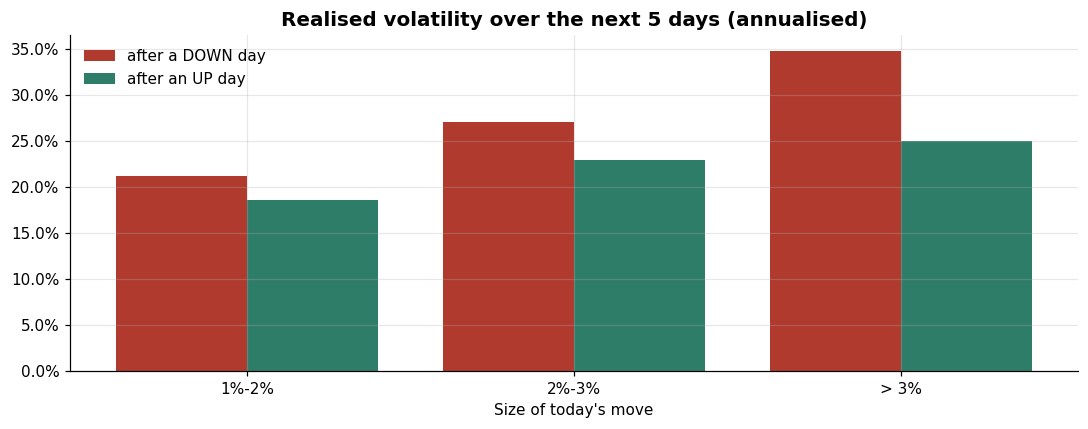

In [6]:
ann = np.sqrt(TRADING_DAYS)
nxt = returns.abs().shift(-1)
fwd5 = returns[::-1].rolling(5).std()[::-1].shift(-1)          # realised vol over the NEXT 5 days
rows = []
for lo, hi in [(0.01, 0.02), (0.02, 0.03), (0.03, 1.0)]:
    dn = (returns <= -lo) & (returns > -hi); up = (returns >= lo) & (returns < hi)
    rows.append({'Move size': f'{lo:.0%}-{hi:.0%}' if hi < 1 else f'> {lo:.0%}',
                 'Down days': int(dn.sum()), 'Up days': int(up.sum()),
                 'Next-day |r| after DOWN': nxt[dn].mean(), 'Next-day |r| after UP': nxt[up].mean(),
                 'Next-5d vol after DOWN': fwd5[dn].mean() * ann, 'Next-5d vol after UP': fwd5[up].mean() * ann})
asy = pd.DataFrame(rows).set_index('Move size')
asy['Down/Up ratio (5d vol)'] = asy['Next-5d vol after DOWN'] / asy['Next-5d vol after UP']
display(asy.style.format({c: '{:.2%}' for c in asy.columns if '|r|' in c} |
                         {c: '{:.1%}' for c in asy.columns if '5d vol' in c} | {'Down/Up ratio (5d vol)': '{:.2f}x'}))

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(asy))
ax.bar(x - 0.2, asy['Next-5d vol after DOWN'], 0.4, color=COLORS['loss'], label='after a DOWN day')
ax.bar(x + 0.2, asy['Next-5d vol after UP'], 0.4, color=COLORS['gain'], label='after an UP day')
ax.set_xticks(x, asy.index); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend()
ax.set_xlabel('Size of today\'s move'); ax.set_title('Realised volatility over the next 5 days (annualised)')
plt.tight_layout(); plt.show()

### 3b. Engle–Ng sign-bias test on Task 6's GARCH residuals
If symmetric GARCH were enough, the *sign* of yesterday's shock shouldn't help predict today's squared standardised residual. We regress
$$z_t^2 = b_0 + b_1 S^-_{t-1} + b_2 S^-_{t-1} z_{t-1} + b_3 S^+_{t-1} z_{t-1} + u_t,\qquad S^-=\mathbf 1_{\{z<0\}},\;S^+=1-S^-$$
A significantly **negative b₂** (big losses raise variance more than GARCH expects) is the leverage effect. The joint test is T·R² ~ χ²(3). Standard errors are heteroskedasticity-robust (HC0).
This is a *diagnostic* with modest power; Section 4's likelihood-ratio test is the formal comparison.

In [7]:
DIST_G, G_FITS = best_dist(asym=False)                         # Task 6's model choice, reproduced
PG = G_FITS[DIST_G]
zg = (returns - PG['mu']) / vol_sigma(returns, PG)
z_lag, y = zg.values[:-1], zg.values[1:] ** 2
Sm = (z_lag < 0).astype(float)
X = np.column_stack([np.ones_like(y), Sm, Sm * z_lag, (1 - Sm) * z_lag])
b = np.linalg.lstsq(X, y, rcond=None)[0]
u = y - X @ b
XtX_inv = np.linalg.inv(X.T @ X)
se = np.sqrt(np.diag(XtX_inv @ (X.T * u ** 2) @ X @ XtX_inv))
r2 = 1 - (u @ u) / ((y - y.mean()) @ (y - y.mean()))
lm = len(y) * r2
sb = pd.DataFrame({'Coefficient': b, 'Robust t': b / se, 'p-value': 2 * stats.norm.sf(np.abs(b / se))},
                  index=['b0 constant', 'b1 sign bias', 'b2 negative size bias', 'b3 positive size bias'])
display(sb.style.format('{:.4f}').map(lambda v: 'font-weight:bold;color:#B03A2E' if isinstance(v, float) and v < 0.05 else '', subset=['p-value']))
SB_P = stats.chi2.sf(lm, 3)
print(f'Joint sign-bias test: T*R^2 = {lm:.2f}, p = {SB_P:.4f} -> '
      + ('symmetric GARCH leaves asymmetry unexplained.' if SB_P < 0.05 else 'no significant asymmetry left by GARCH.'))

,Coefficient,Robust t,p-value
b0 constant,1.0139,10.6386,0.0000
b1 sign bias,0.1792,1.2101,0.2263
b2 negative size bias,0.1654,1.7951,0.0726
b3 positive size bias,-0.1131,-1.3333,0.1824


Joint sign-bias test: T*R^2 = 5.58, p = 0.1337 -> no significant asymmetry left by GARCH.


## 4. Fitting GJR-GARCH
### 4a. Estimates, distribution choice and the GARCH-vs-GJR likelihood-ratio test
Because γ ≥ 0 sits on a boundary, the LR statistic under H₀ (γ = 0) follows a **50:50 mixture of χ²₀ and χ²₁**, so the p-value is half the usual χ²₁ p-value.

In [8]:
DIST, J_FITS = best_dist(asym=True)
P_FULL = J_FITS[DIST]
PG_same = G_FITS[DIST]                                          # GARCH with the same likelihood, for the nested test
LR = 2 * (P_FULL['loglik'] - PG_same['loglik'])
LR_P = 0.5 * stats.chi2.sf(LR, 1)

def col(P):
    return {'μ (daily mean)': P['mu'], 'ω': P['omega'], 'α (gains)': P['alpha'], 'γ (extra for losses)': P['gamma'],
            'α+γ (losses)': P['alpha'] + P['gamma'], 'β': P['beta'], 'ν (t dof)': P['nu'], 'Persistence': P['persistence'],
            'Half-life (days)': P['half_life'], 'Long-run vol (ann.)': P['long_run_vol_ann'],
            'Log-likelihood': P['loglik'], 'AIC': P['aic'], 'BIC': P['bic']}
ptab = pd.DataFrame({f'GARCH ({DIST})': col(PG_same), f'GJR ({DIST})': col(P_FULL),
                     'GJR (other likelihood)': col(J_FITS['normal' if DIST == 't' else 't'])})
display(ptab.style.format(lambda v: f'{v:.3e}' if isinstance(v, float) and 0 < abs(v) < 1e-3 else f'{v:,.4f}', na_rep='-'))
ratio_loss_gain = (P_FULL['alpha'] + P_FULL['gamma']) / max(P_FULL['alpha'], 1e-6)
print(f'BIC prefers the {DIST.upper()} likelihood for GJR.')
print(f'A loss feeds {P_FULL["alpha"] + P_FULL["gamma"]:.3f} of its squared size into tomorrow\'s variance; a gain feeds {P_FULL["alpha"]:.3f}.')
print(f'LR test GJR vs GARCH: LR = {LR:.2f}, p = {LR_P:.2e} -> ' + ('GJR is a significant improvement.' if LR_P < 0.05 else 'no significant improvement.'))
print(f'AIC: GARCH {PG_same["aic"]:,.1f} vs GJR {P_FULL["aic"]:,.1f} | BIC: GARCH {PG_same["bic"]:,.1f} vs GJR {P_FULL["bic"]:,.1f}')

,GARCH (t),GJR (t),GJR (other likelihood)
μ (daily mean),0.0017,0.0014,9.975e-04
ω,4.040e-06,4.101e-06,5.006e-06
α (gains),0.0857,0.0048,0.0070
γ (extra for losses),0.0000,0.1213,0.1100
α+γ (losses),0.0857,0.1261,0.1170
β,0.8970,0.9112,0.9106
ν (t dof),6.7757,7.3693,-
Persistence,0.9827,0.9766,0.9726
Half-life (days),39.6904,29.2966,24.9054
Long-run vol (ann.),0.2425,0.2102,0.2144


BIC prefers the T likelihood for GJR.
A loss feeds 0.126 of its squared size into tomorrow's variance; a gain feeds 0.005.
LR test GJR vs GARCH: LR = 30.57, p = 1.61e-08 -> GJR is a significant improvement.
AIC: GARCH 5,068.3 vs GJR 5,039.7 | BIC: GARCH 5,094.9 vs GJR 5,071.6


### 4b. Cross-check with the `arch` package (robust standard errors)

In [9]:
if HAS_ARCH:
    from arch import arch_model
    am = arch_model(returns * 100, mean='Constant', vol='GARCH', p=1, o=1, q=1,
                    dist='normal' if DIST == 'normal' else 't').fit(disp='off')
    names = {'mu': 'mu', 'omega': 'omega', 'alpha': 'alpha[1]', 'gamma': 'gamma[1]', 'beta': 'beta[1]', 'nu': 'nu'}
    keys = ['mu', 'omega', 'alpha', 'gamma', 'beta'] + (['nu'] if DIST == 't' else [])
    scale = {'mu': 100, 'omega': 1e4}
    xc = pd.DataFrame({'Our engine': [P_FULL[k] for k in keys],
                       'arch package': [am.params[names[k]] / scale.get(k, 1) for k in keys],
                       'Robust t-stat': [am.tvalues[names[k]] for k in keys],
                       'p-value': [am.pvalues[names[k]] for k in keys]}, index=keys)
    xc['Significant 5%'] = np.where(xc['p-value'] < 0.05, 'yes', 'no')
    display(xc.style.format({'Our engine': '{:.6g}', 'arch package': '{:.6g}', 'Robust t-stat': '{:.2f}', 'p-value': '{:.4f}'}))
    print(f'Log-likelihood: ours {P_FULL["loglik"]:,.2f} vs arch {am.loglikelihood:,.2f}')
    print('Note: an alpha close to 0 and not significant is common for equity indices: almost all the ARCH effect comes from losses.')
else:
    print('arch not installed - skipping the cross-check.')

,Our engine,arch package,Robust t-stat,p-value,Significant 5%
mu,0.00142441,0.00142651,4.82,0.0000,yes
omega,4.10068e-06,4.09694e-06,2.99,0.0028,yes
alpha,0.00478355,0.00478151,0.42,0.6710,no
gamma,0.121338,0.121356,4.61,0.0000,yes
beta,0.911166,0.911188,52.37,0.0000,yes
nu,7.36928,7.36488,5.93,0.0000,yes


Log-likelihood: ours -2,513.86 vs arch -2,513.85
Note: an alpha close to 0 and not significant is common for equity indices: almost all the ARCH effect comes from losses.


## 5. News-impact curves: the asymmetry in one picture
Each curve shows how tomorrow's volatility responds to today's shock, starting from the long-run level. EWMA and GARCH are symmetric parabolas. GJR is **steeper on the loss side**.

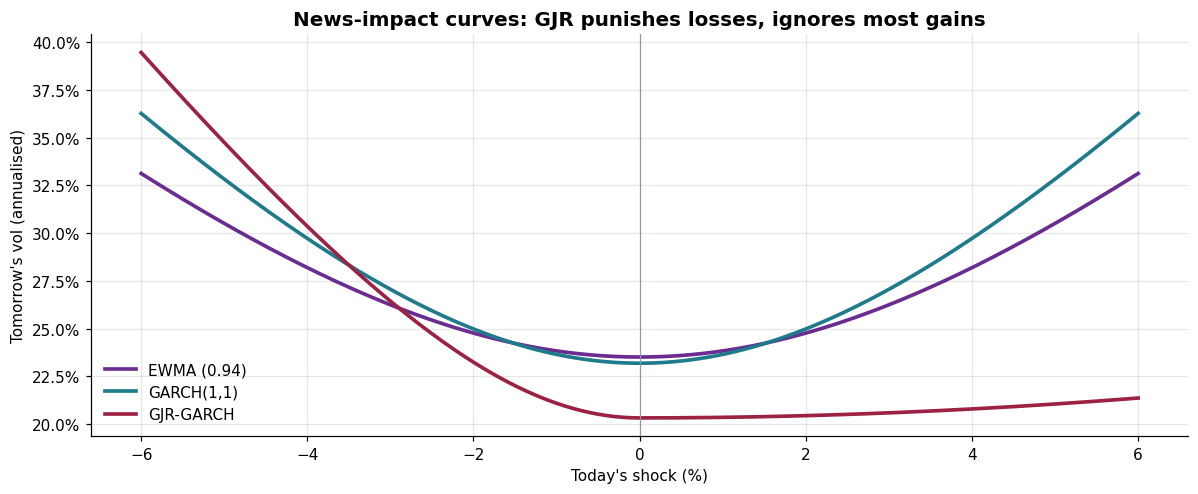

Shock -4%: tomorrow's vol  GARCH 29.7% | GJR 30.4%
Shock +4%: tomorrow's vol  GARCH 29.7% | GJR 20.8%


In [10]:
eps = np.linspace(-0.06, 0.06, 241)
VLg = PG_same['omega'] / (1 - PG_same['persistence'])
VLj = P_FULL['omega'] / (1 - P_FULL['persistence'])
nic = pd.DataFrame({
    'EWMA (0.94)': EWMA_LAMBDA * VLg + (1 - EWMA_LAMBDA) * eps ** 2,
    'GARCH(1,1)': PG_same['omega'] + PG_same['beta'] * VLg + PG_same['alpha'] * eps ** 2,
    'GJR-GARCH': P_FULL['omega'] + P_FULL['beta'] * VLj + (P_FULL['alpha'] + P_FULL['gamma'] * (eps < 0)) * eps ** 2,
}, index=eps)
fig, ax = plt.subplots(figsize=(11, 4.6))
for k, cc in zip(nic, [COLORS['EWMA'], COLORS['GARCH'], COLORS['GJR']]):
    ax.plot(nic.index * 100, np.sqrt(nic[k] * TRADING_DAYS), lw=2.4, color=cc, label=k)
ax.axvline(0, color=COLORS['muted'], lw=0.8)
ax.set_xlabel("Today's shock (%)"); ax.set_ylabel('Tomorrow\'s vol (annualised)')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend()
ax.set_title('News-impact curves: GJR punishes losses, ignores most gains')
plt.tight_layout(); plt.show()
for s in [-0.04, 0.04]:
    i = np.argmin(np.abs(eps - s))
    print(f'Shock {s:+.0%}: tomorrow\'s vol  GARCH {np.sqrt(nic["GARCH(1,1)"].iloc[i] * TRADING_DAYS):.1%} | '
          f'GJR {np.sqrt(nic["GJR-GARCH"].iloc[i] * TRADING_DAYS):.1%}')

## 6. Conditional volatility: where GJR and GARCH disagree

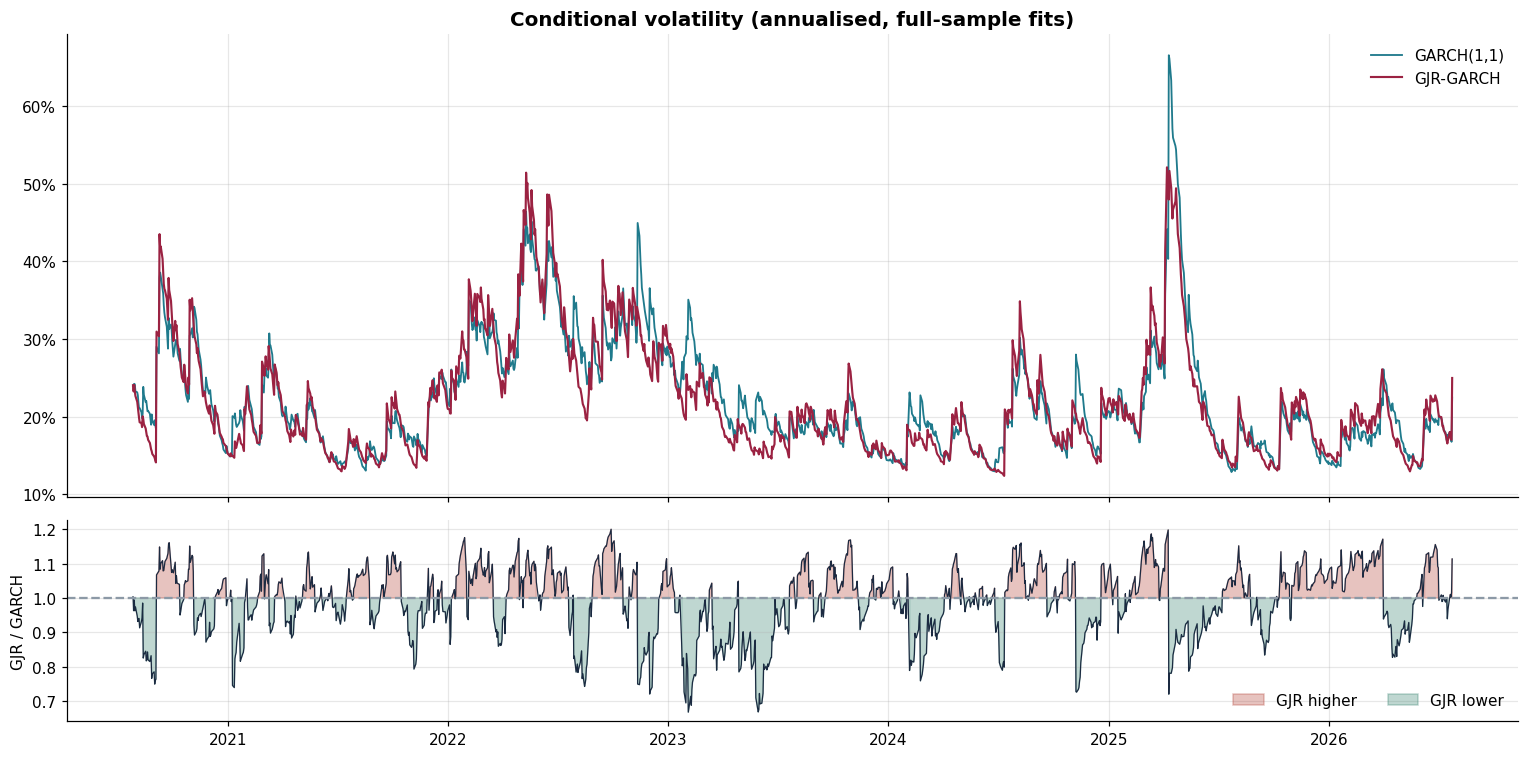

Average GJR/GARCH vol ratio: after a down day 1.014 | after an up day 0.971


In [11]:
sig_g = vol_sigma(returns, PG_same); sig_j = vol_sigma(returns, P_FULL)
ratio = sig_j / sig_g
prev_dn = returns.shift(1) < 0
fig, (a0, a1) = plt.subplots(2, 1, figsize=(14, 7), sharex=True, gridspec_kw={'height_ratios': [2.3, 1]})
a0.plot(sig_g * ann, color=COLORS['GARCH'], lw=1.2, label='GARCH(1,1)')
a0.plot(sig_j * ann, color=COLORS['GJR'], lw=1.4, label='GJR-GARCH')
a0.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); a0.legend(); a0.set_title('Conditional volatility (annualised, full-sample fits)')
a1.plot(ratio, color=COLORS['ink'], lw=0.8); a1.axhline(1, color=COLORS['muted'], ls='--')
a1.fill_between(ratio.index, 1, ratio, where=ratio > 1, color=COLORS['loss'], alpha=0.3, label='GJR higher')
a1.fill_between(ratio.index, 1, ratio, where=ratio < 1, color=COLORS['gain'], alpha=0.3, label='GJR lower')
a1.set_ylabel('GJR / GARCH'); a1.legend(ncol=2)
plt.tight_layout(); plt.show()
print(f'Average GJR/GARCH vol ratio: after a down day {ratio[prev_dn].mean():.3f} | after an up day {ratio[~prev_dn].mean():.3f}')

## 7. Out-of-sample GJR-FHS VaR (re-estimated every 21 days)
This uses exactly the same procedure, start date and refit schedule as Task 6, so the GARCH vs GJR comparison is like for like.

In [12]:
t0 = time.time()
GJR, sig_oos, PHIST = oos_fhs(returns, DIST, asym=True)
print(f'{len(PHIST)} GJR refits in {time.time() - t0:.1f}s | all converged: {PHIST["converged"].all()} | '
      f'first forecast {GJR[(HEADLINE_W, HEADLINE_CL)]["VaR"].first_valid_index():%d %b %Y}')

# Reproduce Task 6 (GARCH) and Tasks 4-5 with the same engine, and check them against their files
GARCH = oos_fhs(returns, DIST_G, asym=False)[0]
HS = build_model('HS'); EWMA = build_model('EWMA')
for name, P_, f in [('HS', HS, 'HS_VaR.csv'), ('EWMA', EWMA, 'EWMA_VaR.csv'), ('GARCH', GARCH, 'GARCH_VaR.csv')]:
    if os.path.exists(f):
        prev = pd.read_csv(f, index_col=0, parse_dates=True)[f'{name}_VaR_{HEADLINE_W}d_{tag(HEADLINE_CL)}_Ret']
        assert np.allclose(prev.dropna(), P_[(HEADLINE_W, HEADLINE_CL)]['VaR'].dropna()), f'{f} mismatch'
        print(f'Consistency check passed: {f} reproduced exactly.')

48 GJR refits in 0.9s | all converged: True | first forecast 21 Jul 2022


Consistency check passed: HS_VaR.csv reproduced exactly.
Consistency check passed: EWMA_VaR.csv reproduced exactly.
Consistency check passed: GARCH_VaR.csv reproduced exactly.


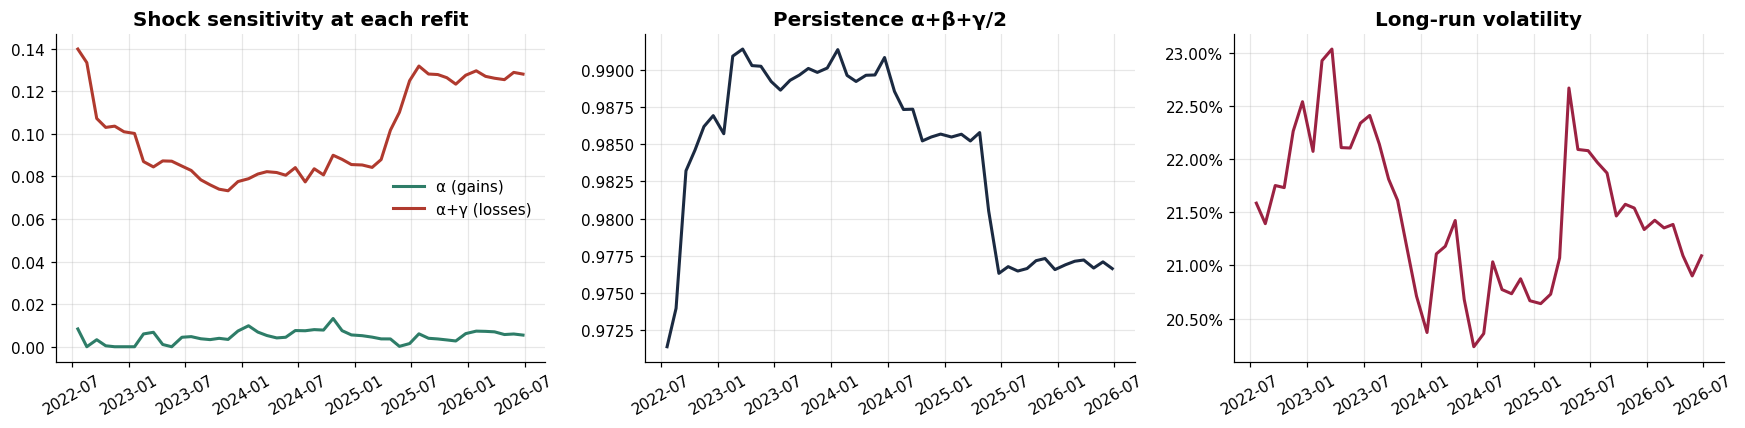

gamma > alpha at 100% of refits: the asymmetry holds up over time, not just in one sub-period.


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(PHIST['alpha'], color=COLORS['gain'], lw=2, label='α (gains)')
axes[0].plot(PHIST['alpha'] + PHIST['gamma'], color=COLORS['loss'], lw=2, label='α+γ (losses)')
axes[0].legend(); axes[0].set_title('Shock sensitivity at each refit')
axes[1].plot(PHIST['persistence'], color=COLORS['ink'], lw=2); axes[1].set_title('Persistence α+β+γ/2')
axes[2].plot(PHIST['long_run_vol_ann'], color=COLORS['GJR'], lw=2)
axes[2].yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); axes[2].set_title('Long-run volatility')
for a in axes: a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()
print(f'gamma > alpha at {(PHIST.gamma > PHIST.alpha).mean():.0%} of refits: the asymmetry holds up over time, not just in one sub-period.')

## 8. Does GJR react faster after losses than after gains?
This compares the next-day VaR change after a large down day and after a large up day. GARCH reacts the same way to both, and GJR should not.

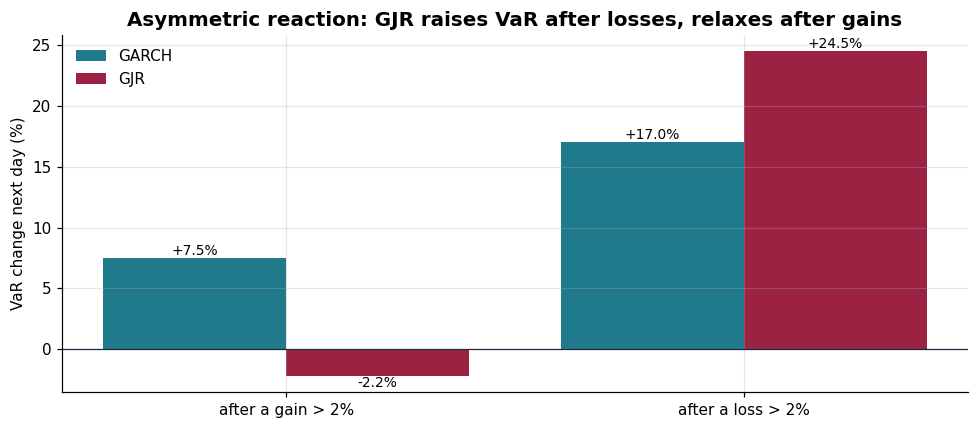

In [14]:
oos = GJR[(HEADLINE_W, HEADLINE_CL)]['VaR'].dropna().index
react = []
for lab, mask in [('after a loss > 2%', returns < -0.02), ('after a gain > 2%', returns > 0.02)]:
    days = [returns.index.get_loc(t) for t in returns[mask].index.intersection(oos) if returns.index.get_loc(t) + 1 < len(returns)]
    for m, P_ in [('GARCH', GARCH), ('GJR', GJR)]:
        v = P_[(HEADLINE_W, HEADLINE_CL)]['VaR']
        react.append({'Event': lab, 'Model': m, 'Days': len(days), 'Avg next-day VaR change': np.mean([v.iloc[p + 1] / v.iloc[p] - 1 for p in days])})
react = pd.DataFrame(react).pivot(index='Event', columns='Model', values='Avg next-day VaR change')
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(react))
ax.bar(x - 0.2, react['GARCH'] * 100, 0.4, color=COLORS['GARCH'], label='GARCH')
ax.bar(x + 0.2, react['GJR'] * 100, 0.4, color=COLORS['GJR'], label='GJR')
for i, (g, j) in enumerate(react[['GARCH', 'GJR']].values * 100):
    ax.text(i - 0.2, g, f'{g:+.1f}%', ha='center', va='bottom' if g >= 0 else 'top', fontsize=9)
    ax.text(i + 0.2, j, f'{j:+.1f}%', ha='center', va='bottom' if j >= 0 else 'top', fontsize=9)
ax.axhline(0, color=COLORS['ink'], lw=0.8); ax.set_xticks(x, react.index); ax.set_ylabel('VaR change next day (%)')
ax.legend(); ax.set_title('Asymmetric reaction: GJR raises VaR after losses, relaxes after gains')
plt.tight_layout(); plt.show()

## 9. Backtest: GJR against the three earlier models on identical dates
Task 8 runs the full battery of tests. Here is the quick coverage view, on dates where every model has a forecast.

In [15]:
ALL = {'HS': HS, 'EWMA': EWMA, 'GARCH': GARCH, 'GJR': GJR}
score = []
for w in WINDOWS:
    common = returns.index
    for P_ in ALL.values(): common = common.intersection(P_[(w, 0.99)]['VaR'].dropna().index)
    t_ = pd.concat([backtest_table(m, P_, dates=common) for m, P_ in ALL.items()])
    score.append(t_[t_.Window == w])
score = pd.concat(score, ignore_index=True)
style_bt(score[score.Confidence == HEADLINE_CL].sort_values(['Window', 'Model']).reset_index(drop=True))

Model,Window,Confidence,Start,Days,Exceptions,Expected,Rate,Kupiec p,Kupiec,Last 250d exc.,Basel zone,Avg VaR %,Avg ES %,VaR churn %
EWMA,250,99.0%,2022-07-21,1006,15,10.1,1.49%,0.145,PASS,4,GREEN,3.56%,4.16%,0.123%
GARCH,250,99.0%,2022-07-21,1006,14,10.1,1.39%,0.239,PASS,4,GREEN,3.47%,4.09%,0.129%
GJR,250,99.0%,2022-07-21,1006,14,10.1,1.39%,0.239,PASS,4,GREEN,3.36%,4.03%,0.129%
HS,250,99.0%,2022-07-21,1006,11,10.1,1.09%,0.769,PASS,2,GREEN,3.57%,4.16%,0.007%
EWMA,500,99.0%,2022-07-21,1006,14,10.1,1.39%,0.239,PASS,3,GREEN,3.51%,4.27%,0.117%
GARCH,500,99.0%,2022-07-21,1006,14,10.1,1.39%,0.239,PASS,3,GREEN,3.42%,4.18%,0.122%
GJR,500,99.0%,2022-07-21,1006,12,10.1,1.19%,0.551,PASS,3,GREEN,3.34%,4.13%,0.122%
HS,500,99.0%,2022-07-21,1006,10,10.1,0.99%,0.985,PASS,0,GREEN,3.95%,4.67%,0.004%
EWMA,750,99.0%,2023-07-20,756,15,7.6,1.98%,0.016,REJECT,5,YELLOW,3.12%,3.79%,0.106%
GARCH,750,99.0%,2023-07-20,756,14,7.6,1.85%,0.035,REJECT,4,GREEN,3.05%,3.74%,0.103%


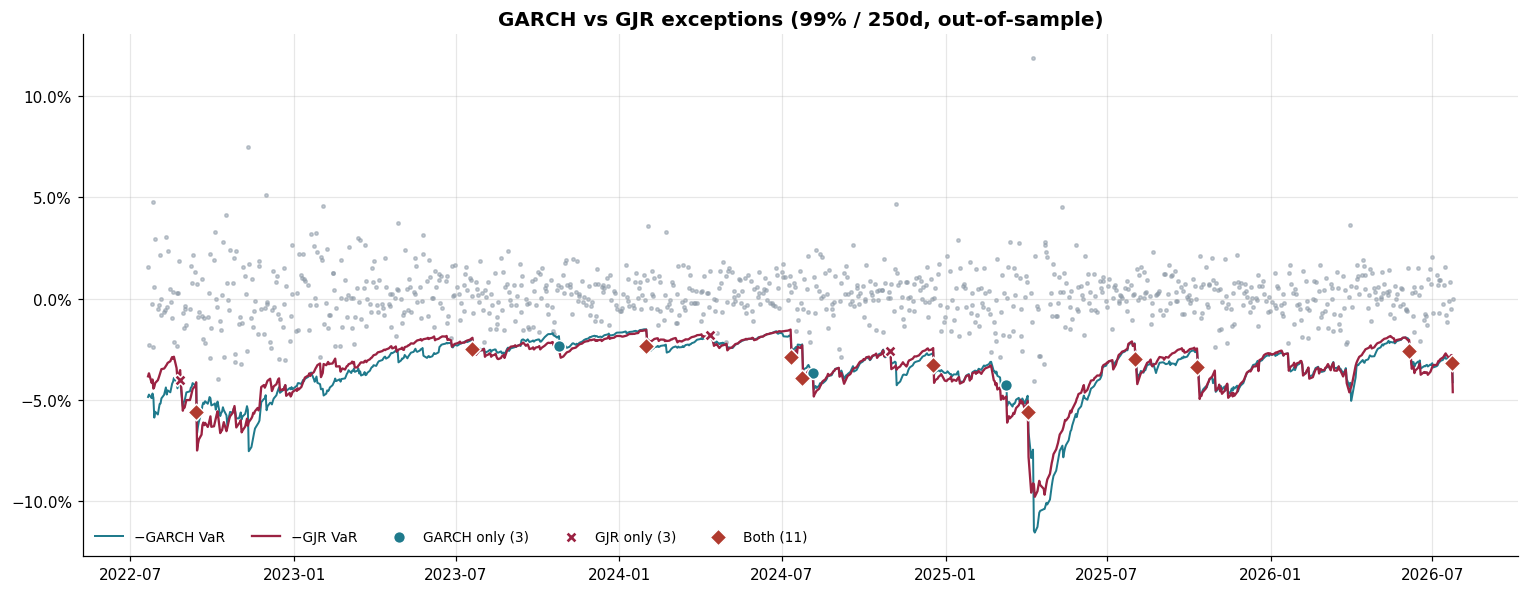

In [16]:
w, c = HEADLINE_W, HEADLINE_CL
d = oos
gb = (returns.reindex(d) < -GARCH[(w, c)]['VaR'].reindex(d)); jb = (returns.reindex(d) < -GJR[(w, c)]['VaR'].reindex(d))
fig, ax = plt.subplots(figsize=(14, 5.5))
ax.scatter(d, returns.reindex(d), s=5, color=COLORS['muted'], alpha=0.5)
ax.plot(-GARCH[(w, c)]['VaR'].reindex(d), color=COLORS['GARCH'], lw=1.3, label='−GARCH VaR')
ax.plot(-GJR[(w, c)]['VaR'].reindex(d), color=COLORS['GJR'], lw=1.5, label='−GJR VaR')
for sel, mk, cc, lab in [(gb & ~jb, 'o', COLORS['GARCH'], 'GARCH only'), (jb & ~gb, 'X', COLORS['GJR'], 'GJR only'), (gb & jb, 'D', COLORS['loss'], 'Both')]:
    ax.scatter(d[sel], returns.reindex(d)[sel], s=60, marker=mk, color=cc, edgecolor='white', zorder=5, label=f'{lab} ({sel.sum()})')
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.legend(ncol=5, fontsize=9, loc='lower left')
ax.set_title(f'GARCH vs GJR exceptions ({c:.0%} / {w}d, out-of-sample)')
plt.tight_layout(); plt.show()

## 10. Export for Tasks 8–9

In [17]:
j_out = export_model('GJR', GJR, 'GJR_VaR.csv')
pd.DataFrame({'GJR_Vol_Daily_OOS': sig_oos, 'GJR_Vol_Daily_FullSample': sig_j,
              'Standardised_Return_FullSample': (returns - P_FULL['mu']) / sig_j}).to_csv('GJR_Volatility.csv')
pd.concat([ptab.T.assign(Spec='full-sample'), PHIST.assign(Spec='out-of-sample refit')]).to_csv('GJR_Parameters.csv')
P_now = fit_vol(returns, DIST, True, P_FULL['_x'])
s_next = vol_next(returns, P_now)
zz = (returns - P_now['mu']) / vol_sigma(returns, P_now)
NEXT = {(w, c): tuple(s_next * np.array(var_es(zz.iloc[-w:], c))) for w in WINDOWS for c in CONFIDENCES}
bt_j = backtest_table('GJR', GJR)
update_summary(bt_j, NEXT)
summary = pd.read_csv(SUMMARY_FILE)
summary.query('Window == @HEADLINE_W and Confidence == @HEADLINE_CL')[
    ['Model', 'Start', 'Days', 'Exceptions', 'Expected', 'Kupiec p', 'Basel zone', 'Avg VaR %', 'Next-day VaR $', 'Next-day ES $']]

Saved GJR_VaR.csv (1,506 rows x 48 cols) + data dictionary
VaR_Model_Summary.csv now holds models: ['EWMA', 'GARCH', 'GJR', 'HS']


,Model,Start,Days,Exceptions,Expected,Kupiec p,Basel zone,Avg VaR %,Next-day VaR $,Next-day ES $
1,HS,2021-07-23,1256,22,12.5600,0.0155,GREEN,0.0353,"126,797.4731","143,752.2396"
10,EWMA,2021-07-23,1256,18,12.5600,0.1474,GREEN,0.0373,"173,974.3428","208,774.7597"
19,GARCH,2022-07-21,1006,14,10.0600,0.2385,GREEN,0.0347,"188,721.9343","229,167.3729"
28,GJR,2022-07-21,1006,14,10.0600,0.2385,GREEN,0.0336,"210,394.7895","247,131.3481"


## 11. Executive summary

In [18]:
sc = score[(score.Window == HEADLINE_W) & (score.Confidence == HEADLINE_CL)].set_index('Model')
g, j = sc.loc['GARCH'], sc.loc['GJR']
nd = summary.set_index('Model').query('Window == @HEADLINE_W and Confidence == @HEADLINE_CL')['Next-day VaR $']
display(Markdown(f"""
**Is there an asymmetry?** Yes. After a 2–3% move, volatility over the next five days was **{asy.iloc[1]['Down/Up ratio (5d vol)']:.2f}x** higher after down days than after up days.
{'The Engle–Ng sign-bias test on Task 6 residuals also detects it (p = ' + format(SB_P, '.3f') + ').' if SB_P < 0.05 else 'The Engle–Ng sign-bias test does not detect it at 5% (p = ' + format(SB_P, '.2f') + '). That test has low power and only looks one day back; the likelihood-ratio test below compares the full models and is decisive.'}

**Fitted GJR ({DIST} likelihood).** α = {P_FULL['alpha']:.3f} for gains and α + γ = {P_FULL['alpha'] + P_FULL['gamma']:.3f} for losses,
persistence {P_FULL['persistence']:.3f} (half-life {P_FULL['half_life']:.0f} days). The LR test against GARCH gives **p = {LR_P:.1e}**, and BIC
{'prefers GJR' if P_FULL['bic'] < PG_same['bic'] else 'prefers GARCH'} ({P_FULL['bic']:,.0f} vs {PG_same['bic']:,.0f}). γ exceeded α at {(PHIST.gamma > PHIST.alpha).mean():.0%} of the out-of-sample refits.

**Does it help the VaR?** On {int(g.Days)} identical out-of-sample days (99% / 250d, {g.Expected:.1f} exceptions expected): GARCH **{int(g.Exceptions)}**
exceptions (Kupiec p = {g['Kupiec p']:.3f}, average VaR {g['Avg VaR %']:.2%}) vs GJR **{int(j.Exceptions)}** (p = {j['Kupiec p']:.3f}, average VaR {j['Avg VaR %']:.2%}).
{'GJR gets the same or better coverage with a *lower* average VaR, which means less capital.' if (j.Exceptions <= g.Exceptions and j['Avg VaR %'] < g['Avg VaR %']) else ''} After a loss larger than 2%, GJR raises VaR by
{react.loc['after a loss > 2%', 'GJR']:+.1%} the next day (GARCH {react.loc['after a loss > 2%', 'GARCH']:+.1%}). After a gain larger than 2%, GJR changes VaR by {react.loc['after a gain > 2%', 'GJR']:+.1%}
(GARCH {react.loc['after a gain > 2%', 'GARCH']:+.1%}). Next-day 99% VaR on NAV {money(NAV)}: **{money(nd.get('GJR', np.nan))}**.

**Takeaway.** The leverage effect is **statistically clear** in the volatility dynamics. Whether that turns into *better VaR forecasts* is a separate
question, and a better fit in sample doesn't guarantee better tail forecasts. **Task 8** answers it with the full backtest battery (Kupiec, Christoffersen, ES and Basel)
on all four models, and **Task 9** ranks them with proper scoring rules and significance tests.
"""))


**Is there an asymmetry?** Yes. After a 2–3% move, volatility over the next five days was **1.18x** higher after down days than after up days.
The Engle–Ng sign-bias test does not detect it at 5% (p = 0.13). That test has low power and only looks one day back; the likelihood-ratio test below compares the full models and is decisive.

**Fitted GJR (t likelihood).** α = 0.005 for gains and α + γ = 0.126 for losses,
persistence 0.977 (half-life 29 days). The LR test against GARCH gives **p = 1.6e-08**, and BIC
prefers GJR (5,072 vs 5,095). γ exceeded α at 100% of the out-of-sample refits.

**Does it help the VaR?** On 1006 identical out-of-sample days (99% / 250d, 10.1 exceptions expected): GARCH **14**
exceptions (Kupiec p = 0.239, average VaR 3.47%) vs GJR **14** (p = 0.239, average VaR 3.36%).
GJR gets the same or better coverage with a *lower* average VaR, which means less capital. After a loss larger than 2%, GJR raises VaR by
+24.5% the next day (GARCH +17.0%). After a gain larger than 2%, GJR changes VaR by -2.2%
(GARCH +7.5%). Next-day 99% VaR on NAV $4,520,228: **$210,395**.

**Takeaway.** The leverage effect is **statistically clear** in the volatility dynamics. Whether that turns into *better VaR forecasts* is a separate
question, and a better fit in sample doesn't guarantee better tail forecasts. **Task 8** answers it with the full backtest battery (Kupiec, Christoffersen, ES and Basel)
on all four models, and **Task 9** ranks them with proper scoring rules and significance tests.


---
*Task 7 complete. Four VaR models (HS, EWMA, GARCH, GJR) now share one schema, ready for formal backtesting.*

*Prepared by Arham Shah.*